# Liver-versus-brain TE + DGE quantitative analysis

Executed companion notebook for the preliminary manuscript. Source snapshot: `Kays3/TE_Ocean_Acidification` commit `8d2a294`.

## tl;dr

The analysis separates pooled screening tests from matched-stratum inference. Conclusions below are generated from executed outputs.

In [1]:
from pathlib import Path
import subprocess
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if ROOT.name != 'quantitative-analysis':
    ROOT = ROOT / 'manuscript/draft-01-preliminary/quantitative-analysis'
subprocess.run(['python3', str(ROOT/'run_analysis.py')], check=True)
print('Analysis completed:', ROOT/'output')

Analysis completed: /Users/kaisardauyey/workspace/research1/TE_OA_Intergenerational_Paper/manuscript/draft-01-preliminary/quantitative-analysis/output


In [2]:
display(Markdown((ROOT/'output/analysis-summary.md').read_text()))

# Liver-versus-brain TE + DGE quantitative analysis

## Executive result

At the pooled result-row level, liver had a higher FDR-significant rate than brain for both genes (3.341% vs 2.637%; odds ratio 1.28, BH-adjusted Fisher P 1.4e-20) and strict TEs (2.021% vs 1.579%; odds ratio 1.29, BH-adjusted Fisher P 0.0736). These row-level tests are highly powered but anti-conservative because the same features recur across contrasts.

Across the six matched phenotype-by-contrast strata, liver had the higher strict-TE rate in 3 strata and brain in 3. The exact paired sign-flip test gave BH-adjusted P 0.938; this matched-stratum result is the preferred tissue-level inference.

For TE-gene association screening, 15,637/109,799 liver pairs and 12,566/55,488 brain pairs had stable direction and approximate Spearman FDR < 0.05. The pooled pair-level odds ratio was 0.57 (Fisher P <2.2e-308), but this is descriptive only because candidate pairs share TEs and genes. After collapsing to one summary per TE, brain TEs had a higher median fraction of FDR-significant candidate genes (0.486 vs 0.247; BH-adjusted Mann-Whitney P 6.55e-06, Cliff's delta for liver-minus-brain -0.43) and a modestly higher maximum robust score (0.681 vs 0.622; BH-adjusted P 0.0245).

## Statistical hierarchy

1. **Preferred tissue inference:** exact sign-flip tests on log rate ratios across six matched parental-phenotype-by-contrast strata.
2. **Stratum localization:** Fisher exact tests within each matched stratum, BH-adjusted across 18 tissue comparisons.
3. **Pooled sensitivity:** Fisher exact tests on all result rows; useful descriptively but not independent.
4. **TE-gene screening:** Mann-Whitney tests after collapsing candidate pairs to one summary per TE, with Cliff's delta and BH correction.

## Key limitations

- Differential-result rows are not biological replicates; features recur across contrasts.
- Only 30 brain and 30 liver libraries are represented in the compact correlation analysis.
- Liver and brain differ in sequencing depth and mapping composition.
- TE-gene correlations are screening associations, not causal regulation.
- Compact inputs do not contain raw sample-level counts, so a joint tissue-by-treatment count model cannot be refit here.
- Approximate Spearman FDR values inherit the assumptions of the upstream residual-correlation workflow.

## Source

Input snapshot copied from `Kays3/TE_Ocean_Acidification` commit `8d2a294` (remote `main`) on 31 July 2026. Checksums are recorded in `input_checksums.csv`.


## Context & Methods

### Key assumptions

- The six parental-phenotype-by-contrast strata are the preferred matched tissue units.
- Pooled differential-result rows are non-independent because features recur across contrasts.
- TE-gene pairs share TEs and genes, so per-TE collapsed tests are preferred over raw pair-level tests.
- The compact snapshot does not support refitting a joint DESeq2 tissue interaction.

## Data

In [3]:
checksums=pd.read_csv(ROOT/'output/input_checksums.csv')
display(checksums)

,file,bytes,sha256
0,aggregate_summary.csv,558,3cdfb051e6454c0955651c60b32017073ff0154ec29dfb...
1,brain_ranked_candidates.csv.gz,3083605,52ecdd871472967027285b2736fa1e35ea47aa3d3a6c8f...
2,brain_top5_candidates.csv,3615,1e445531ad9cf53ddce7326a2a90e71605c582514b5a6d...
3,liver_ranked_candidates.csv.gz,6215848,21b5d10325492f26fb0627c8bdcc0b7e978762a716aa5f...
4,liver_top5_candidates.csv,3731,4ef40e4b37594d3100e1c77c9e3bf51fc670efa3d5551c...
5,matched_tissue_comparison.csv,2666,f54d0161774927b8842341d10851e47771ad60776f7bc4...
6,star_qc_by_tissue.csv,673,2cb3cf04d02ca38ec6cbdc6a68d850c6254ef890725640...
7,summary_by_stratum.csv,3917,7095524aff8da85fa55468e0a11a22fd1d790fbb851cf6...
8,te_gene_analysis_summary.csv,446,2f46732095e0749d96bfb0ee89c449bb4e0e69706de540...
9,within_tissue_gene_repeat_comparison.csv,3047,9eaca349ec9499a4e0a14613ee0bc330ed8f9cae77a97d...


## Results

In [4]:
pooled=pd.read_csv(ROOT/'output/pooled_tissue_tests.csv')
paired=pd.read_csv(ROOT/'output/matched_stratum_paired_tests.csv')
te_tests=pd.read_csv(ROOT/'output/te_gene_per_te_tests.csv')
display(pooled)
display(paired)
display(te_tests)

,analysis_type,endpoint,brain_events,brain_tested,brain_rate,liver_events,liver_tested,liver_rate,liver_vs_brain_odds_ratio,odds_ratio_ci_low,odds_ratio_ci_high,fisher_p,fisher_padj_bh
0,gene,significant,2982,113088,0.026369,3265,97711,0.033415,1.276448,1.213706,1.342433,2.333429e-21,1.400058e-20
1,gene,strong_significant,1568,113088,0.013865,1530,97711,0.015658,1.131381,1.053881,1.214580,6.872360e-04,1.374472e-03
2,all_repeat,significant,186,12919,0.014397,229,12509,0.018307,1.276600,1.050380,1.551541,1.520319e-02,1.824383e-02
3,all_repeat,strong_significant,95,12919,0.007354,155,12509,0.012391,1.693651,1.310367,2.189046,5.700837e-05,1.710251e-04
4,strict_TE,significant,93,5891,0.015787,122,6037,0.020209,1.285880,0.979430,1.688214,7.356578e-02,7.356578e-02
5,strict_TE,strong_significant,51,5891,0.008657,87,6037,0.014411,1.674345,1.182795,2.370175,3.504372e-03,5.256557e-03


,analysis_type,matched_strata,median_liver_vs_brain_log2_rate_ratio,mean_liver_vs_brain_log2_rate_ratio,liver_higher_strata,brain_higher_strata,exact_sign_flip_p,exact_sign_flip_padj_bh
0,gene,6,0.587149,0.394183,4,2,0.50000,0.9375
1,all_repeat,6,0.506176,0.093756,4,2,0.93750,0.9375
2,strict_TE,6,0.531615,0.148069,3,3,0.84375,0.9375


,metric,brain_tes,brain_median,liver_tes,liver_median,mannwhitney_u,mannwhitney_p,cliffs_delta_liver_minus_brain,mannwhitney_padj_bh
0,significant_pair_fraction,73,0.485765,93,0.247253,1920.5,0.000002,-0.434232,0.000007
1,median_robust_score,73,0.192857,93,0.146429,2331.0,0.000543,-0.313301,0.000725
2,max_robust_score,73,0.680534,93,0.622247,2702.5,0.024467,-0.203859,0.024467
3,median_abs_rho_residual,73,0.267631,93,0.218242,2193.0,0.000093,-0.353955,0.000187


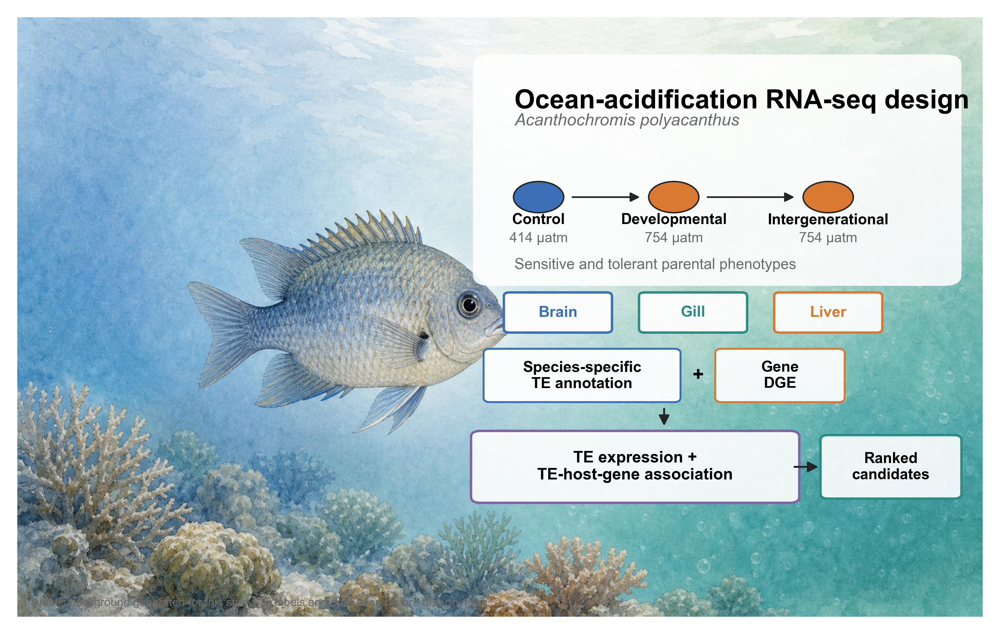

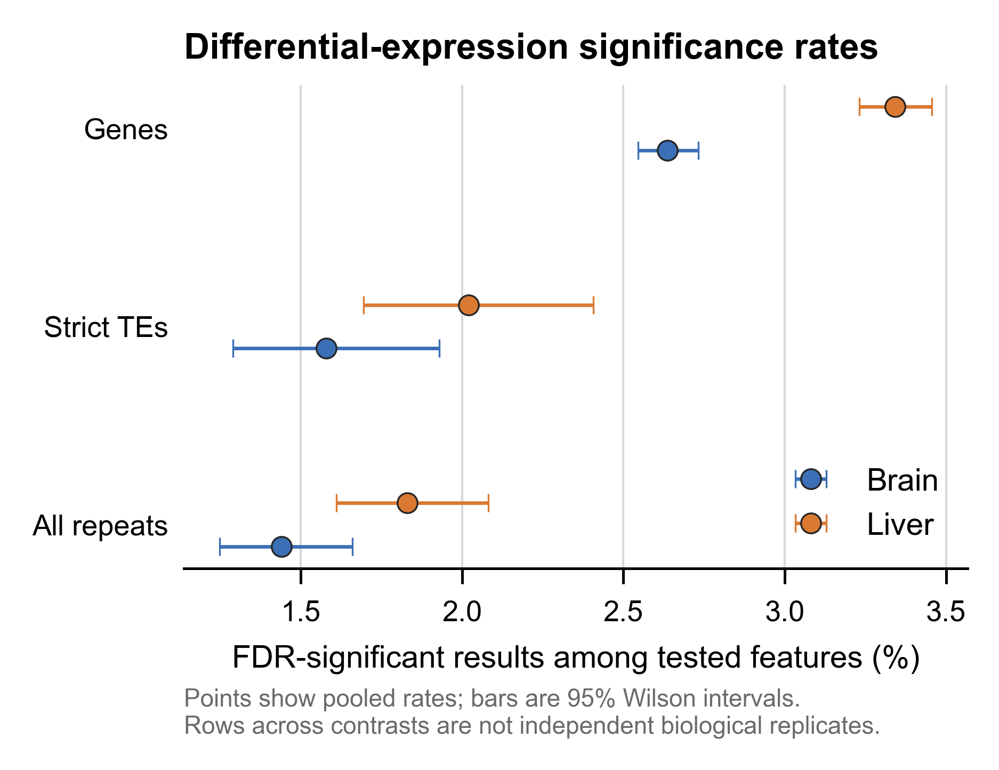

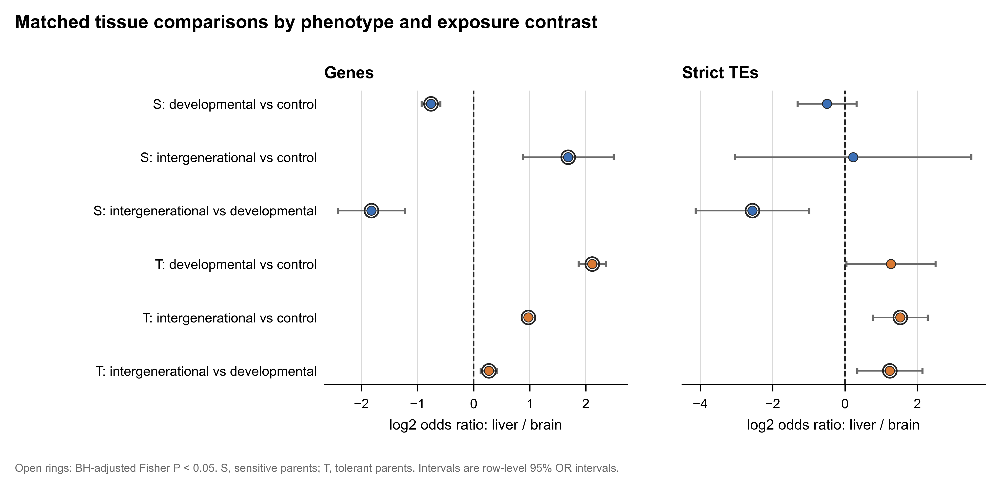

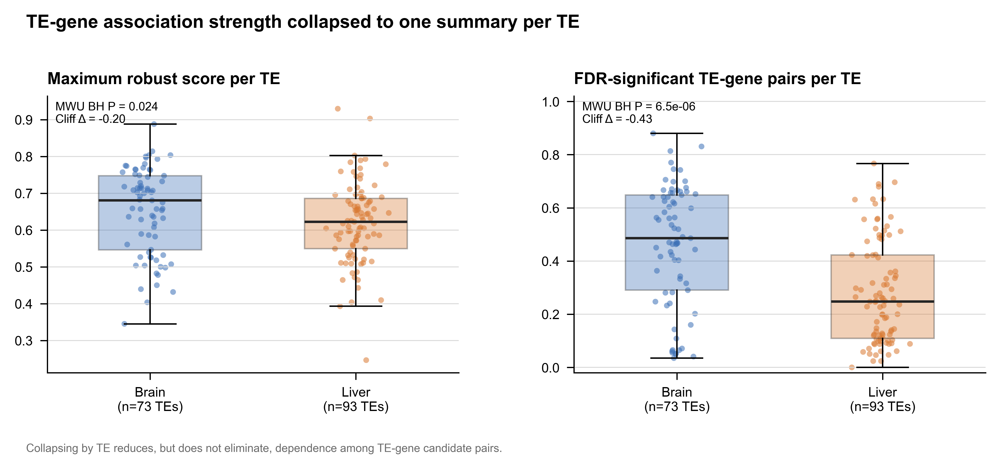

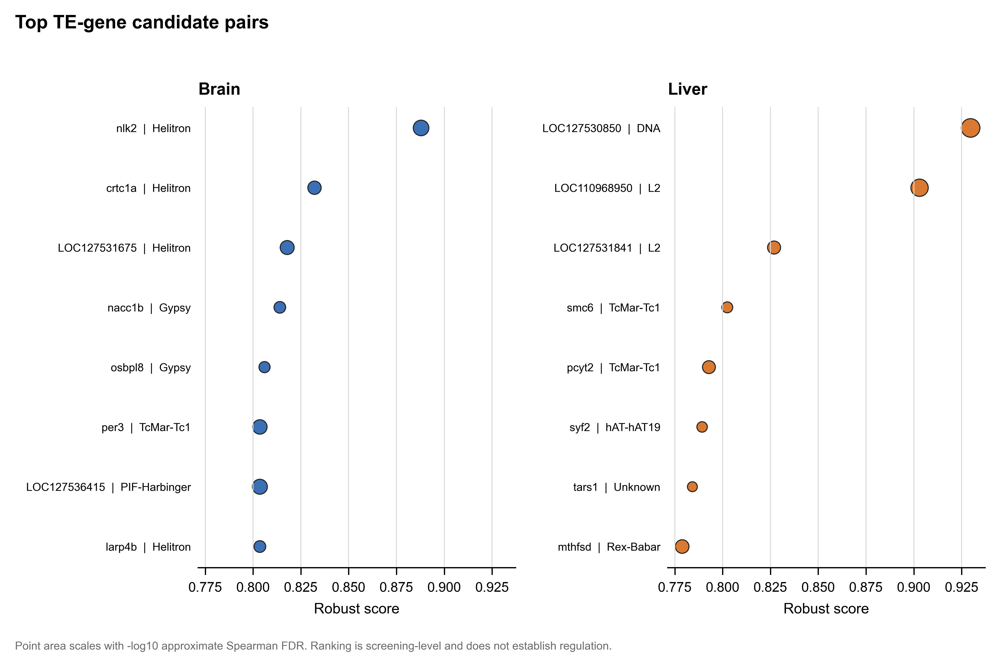

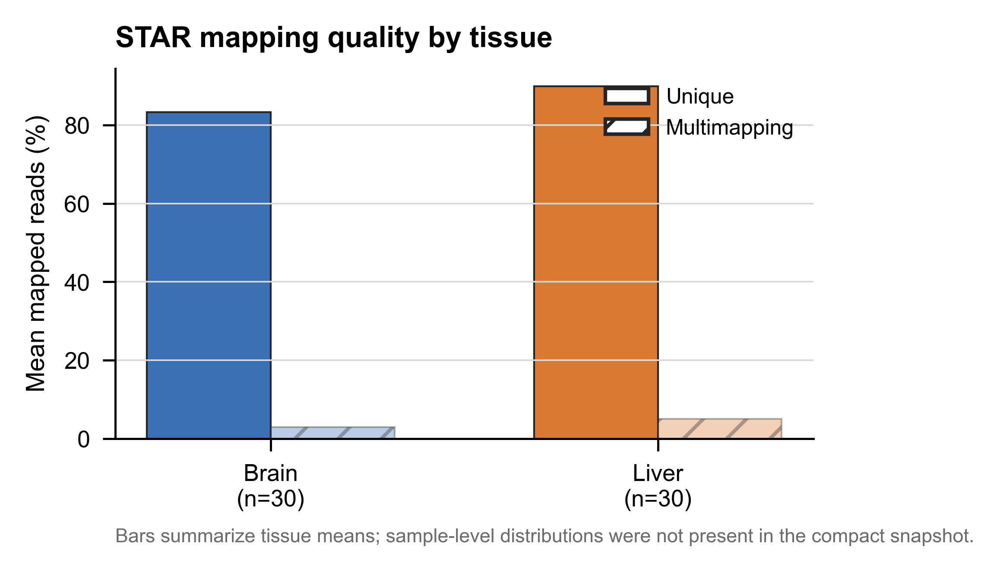

In [5]:
for name in ['figure-1-artistic-study-design.png','figure-2-dge-te-significance-rates.png','figure-3-matched-stratum-odds-ratios.png','figure-4-per-te-association-summary.png','figure-5-top-te-gene-candidates.png','figure-s2-star-mapping-qc.png']:
    display(Image(filename=str(ROOT/'output/figures'/name), width=900))

## Takeaways

- Pooled rows favour liver for overall gene and repeat discovery rates, but strict-TE pooled significance is not BH-significant.
- The matched six-stratum tests do not support a consistent liver-versus-brain difference.
- Brain TE-gene associations are stronger after collapsing to one summary per TE.
- All TE-gene results remain screening-level associations, not evidence of regulation or mobilization.